# Marine Lobster Holding Tank: Telemetry & Health Assessment

## 1. The Biological Problem (Fuzzy Logic vs. Strict Thresholds)
In commercial aquaculture, water quality does not instantly switch from "Safe" to "Deadly". Biological stress happens on a gradient. For example, lobsters are perfectly comfortable at a Salinity of 30 PPT. At 27 PPT, they don't immediately die, but they experience "Osmotic Stress" (Warning). Below 25 PPT, they experience Osmotic Shock (Critical).

To teach our AI how lobsters feel, we use **Fuzzy Logic Membership Functions (Trapezoids)** based on published marine biology literature:
*   **Optimal (Score = 1):** The ideal range for crustacean growth.
*   **Warning (Score 0 to 1):** The sloped lines. The water is degrading, and the lobster is becoming stressed. Operators have a 30-60 minute window to act.
*   **Critical (Score = 0):** Lethal limits. Immediate water flush required.

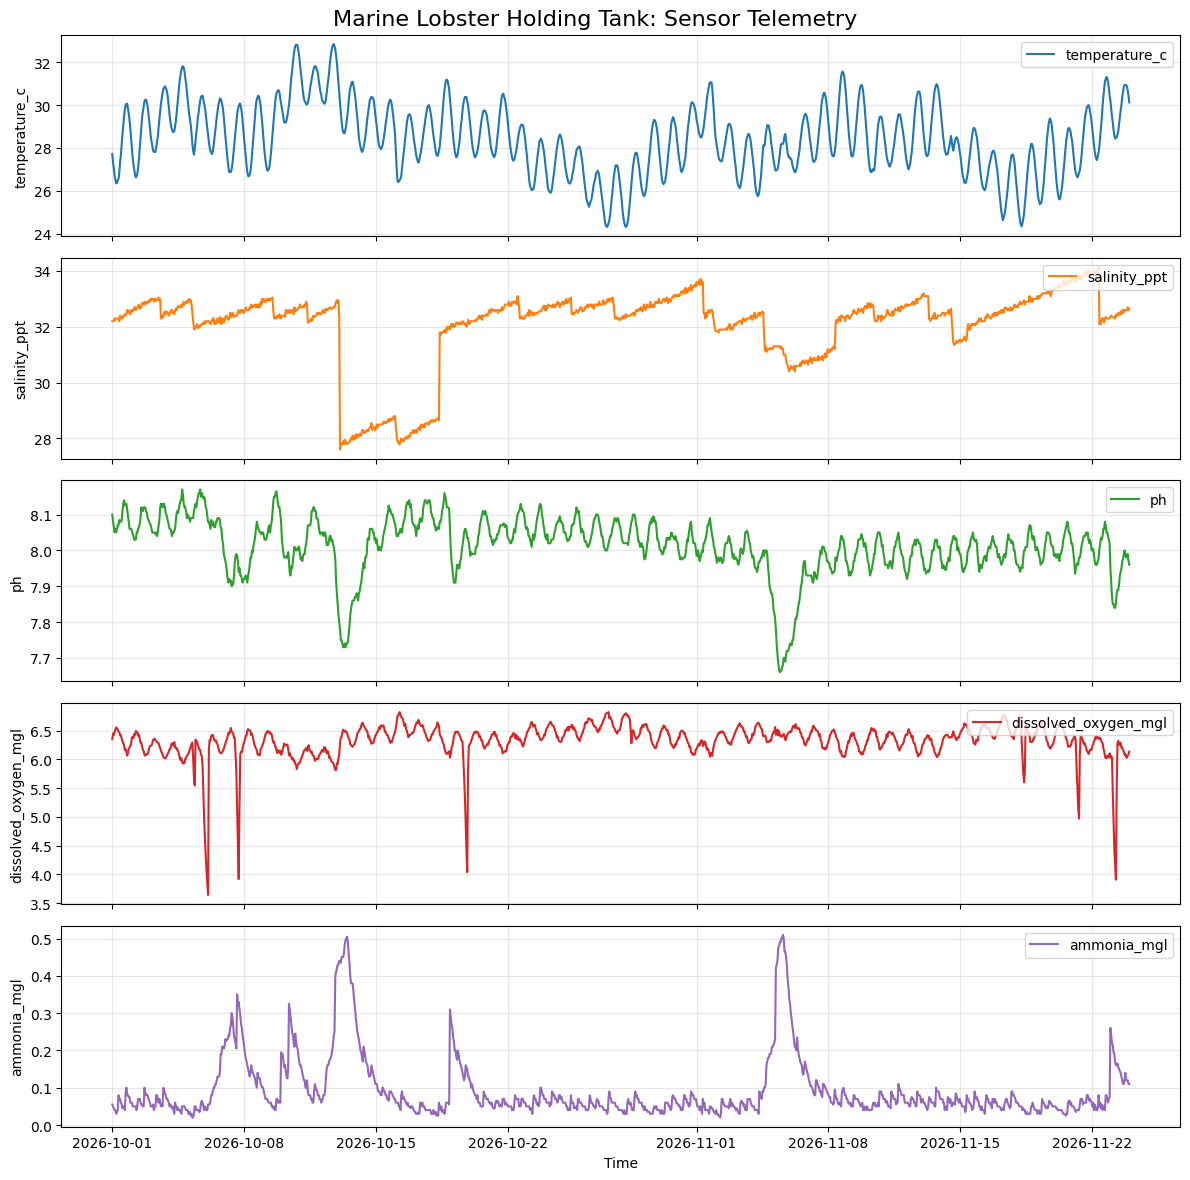

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset (point this to your actual CSV location)
df = pd.read_csv('../../Claude/train_placeholder.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
sensors = ["temperature_c", "salinity_ppt", "ph", "dissolved_oxygen_mgl", "ammonia_mgl"]

# 2. Time-Series Plot (To show 24-hour biological cycles)
fig, axes = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
for i, var in enumerate(sensors):
    axes[i].plot(df['timestamp'], df[var], label=var, color=f"C{i}")
    axes[i].set_ylabel(var)
    axes[i].legend(loc="upper right")
    axes[i].grid(True, alpha=0.3)

plt.xlabel("Time")
plt.suptitle("Marine Lobster Holding Tank: Sensor Telemetry", fontsize=16, y=0.98)
plt.tight_layout()
plt.savefig("timeseries_plot.png", dpi=300)
plt.show()

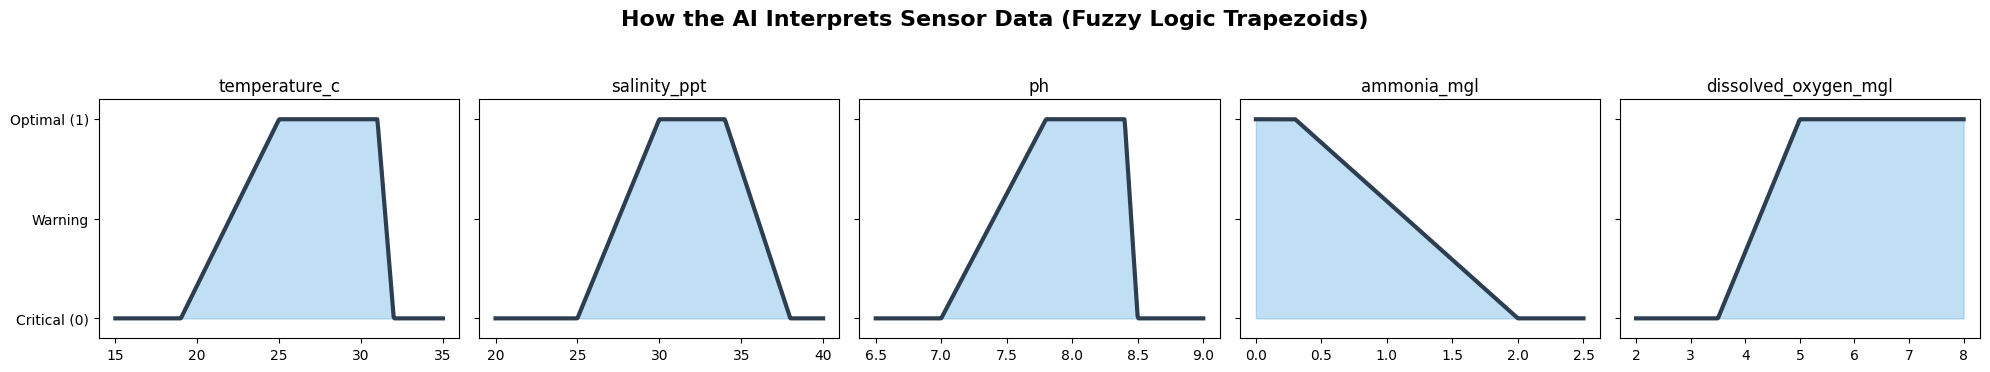

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings("ignore")

def trap(x, a, b, c, d):
    """Calculates Trapezoidal Fuzzy Membership (0 to 1)"""
    x = np.asarray(x, float)
    up = np.where(b > a, (x - a) / max(b - a, 1e-9), (x >= b) * 1.0)
    dn = np.where(d > c, (d - x) / max(d - c, 1e-9), (x <= c) * 1.0)
    return np.clip(np.minimum(up, dn), 0, 1)

# Biological limits based on literature (Panulirus spp.)
SOURCES = {
    "temperature_c": (19, 25, 31, 32),       # Optimal: 25-31°C
    "salinity_ppt": (25, 30, 34, 38),        # Optimal: 30-34 PPT
    "ph": (7.0, 7.8, 8.4, 8.5),              # Optimal: 7.8-8.4
    "ammonia_mgl": (-1e3, -1e3, 0.3, 2.0),   # Optimal: <0.3 mg/L
    "dissolved_oxygen_mgl": (3.5, 5.0, 1e3, 1e3) # Optimal: >5.0 mg/L
}

fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
ranges = {
    "temperature_c": (15, 35), "salinity_ppt": (20, 40),
    "ph": (6.5, 9.0), "ammonia_mgl": (0, 2.5), "dissolved_oxygen_mgl": (2, 8)
}

for i, (var, mf) in enumerate(SOURCES.items()):
    x = np.linspace(ranges[var][0], ranges[var][1], 400)
    y = trap(x, *mf)
    axes[i].plot(x, y, lw=3, color='#2c3e50')
    axes[i].fill_between(x, y, color='#3498db', alpha=0.3)
    axes[i].set_title(var, fontsize=12)
    axes[i].set_ylim(-0.1, 1.1)
    axes[i].set_yticks([0, 0.5, 1])
    axes[i].set_yticklabels(['Critical (0)', 'Warning', 'Optimal (1)'])
    if i > 0: axes[i].set_yticklabels([])

plt.suptitle("How the AI Interprets Sensor Data (Fuzzy Logic Trapezoids)", y=1.05, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. Real-Time Telemetry & Status Overlay
High-frequency sensors (polling every 5 seconds) generate mechanical noise. By mapping the raw data against our Fuzzy Logic rules, we can visualize exactly when the holding tank drifted from Optimal to Warning, giving warehouse staff the visual proof of *why* an alert was generated.

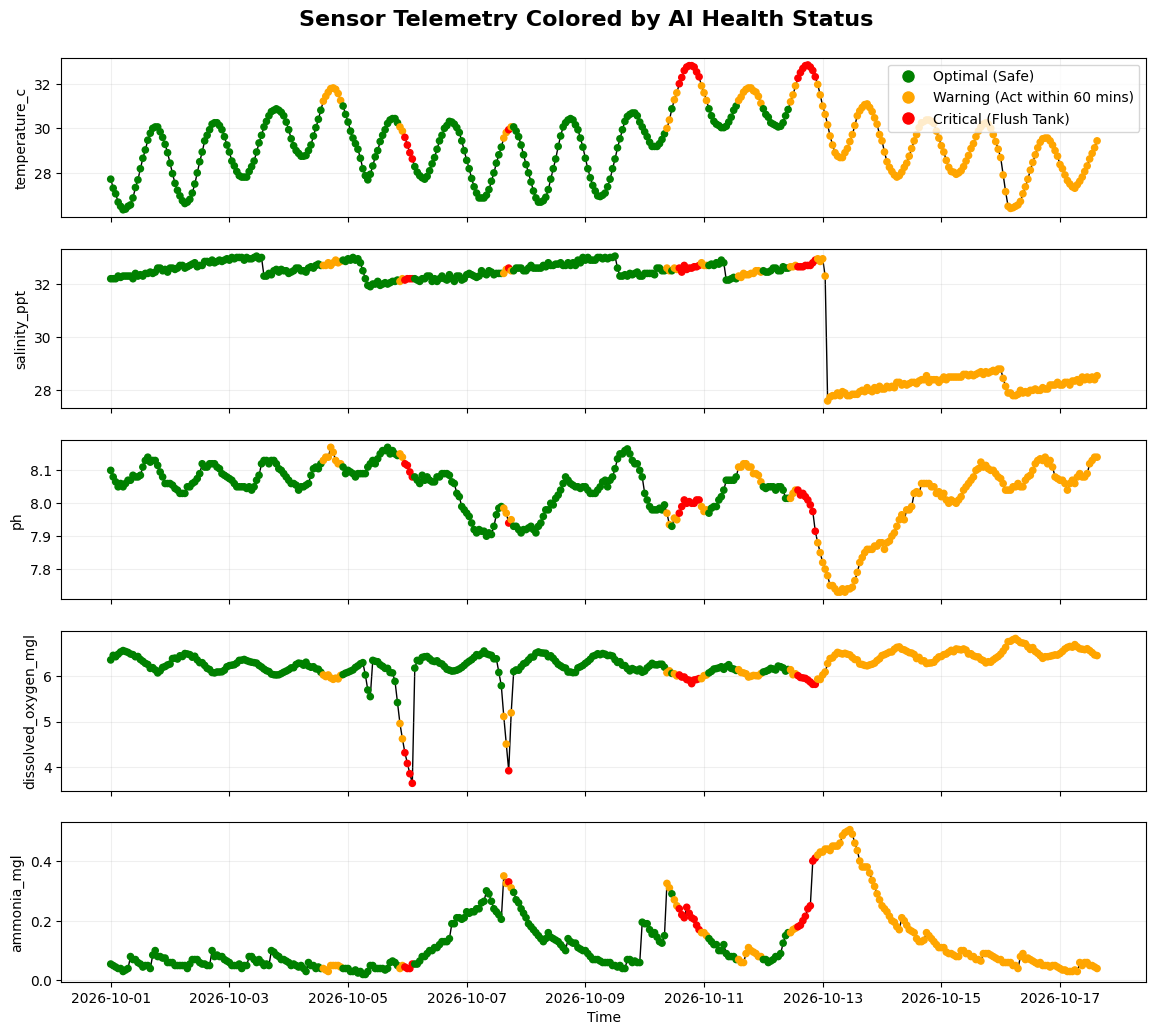

In [6]:
# Load raw dataset
df = pd.read_csv("../../Claude/train_placeholder.csv")
df['timestamp'] = pd.to_datetime(df['timestamp'])
df_slice = df.iloc[:400] # Take a slice for visual clarity

colors = {'Optimal': 'green', 'Warning': 'orange', 'Critical': 'red'}
fig2, axes2 = plt.subplots(5, 1, figsize=(14, 12), sharex=True)

for i, var in enumerate(["temperature_c", "salinity_ppt", "ph", "dissolved_oxygen_mgl", "ammonia_mgl"]):
    axes2[i].plot(df_slice['timestamp'], df_slice[var], color='black', lw=1, zorder=1)
    axes2[i].scatter(df_slice['timestamp'], df_slice[var], c=df_slice['fuzzy_status'].map(colors), s=20, zorder=2)
    axes2[i].set_ylabel(var)
    axes2[i].grid(True, alpha=0.2)

# Custom legend for the end-user
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='green', markersize=10, label='Optimal (Safe)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=10, label='Warning (Act within 60 mins)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=10, label='Critical (Flush Tank)')
]
axes2[0].legend(handles=legend_elements, loc='upper right')

plt.xlabel("Time")
plt.suptitle("Sensor Telemetry Colored by AI Health Status", y=0.92, fontsize=16, fontweight='bold')
plt.show()

## 3. Sensor Correlation
Why do we need a complex multivariate model (VAR) instead of just looking at one sensor at a time? Because physical water properties interact. As shown below, Ammonia and pH have a strong negative correlation. As Ammonia spikes, the water becomes acidic (pH drops).

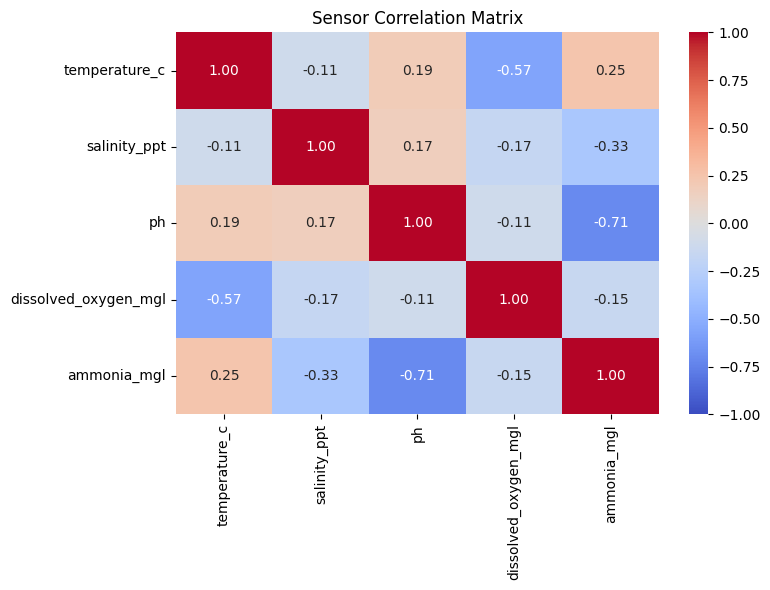

In [7]:
sensors = ["temperature_c", "salinity_ppt", "ph", "dissolved_oxygen_mgl", "ammonia_mgl"]
plt.figure(figsize=(8, 6))
corr_matrix = df[sensors].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Sensor Correlation Matrix")
plt.tight_layout()
plt.show()

--- Numerical Forecast Accuracy (1-Hour Ahead) ---
Sensor: ammonia_mgl, Winning Model MAE: 0.0064
Sensor: dissolved_oxygen_mgl, Winning Model MAE: 0.03
Sensor: ph, Winning Model MAE: 0.0083
Sensor: salinity_ppt, Winning Model MAE: 0.0707
Sensor: temperature_c, Winning Model MAE: 0.0521


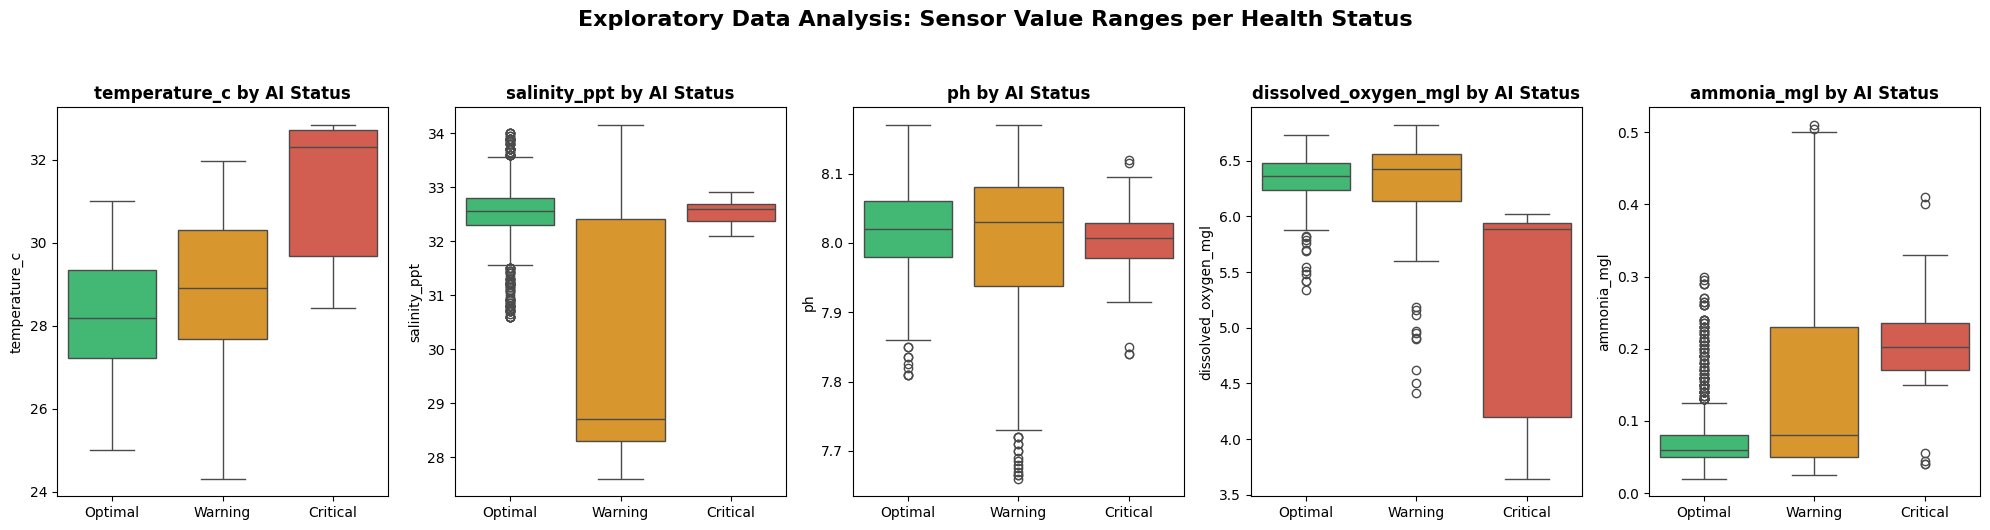

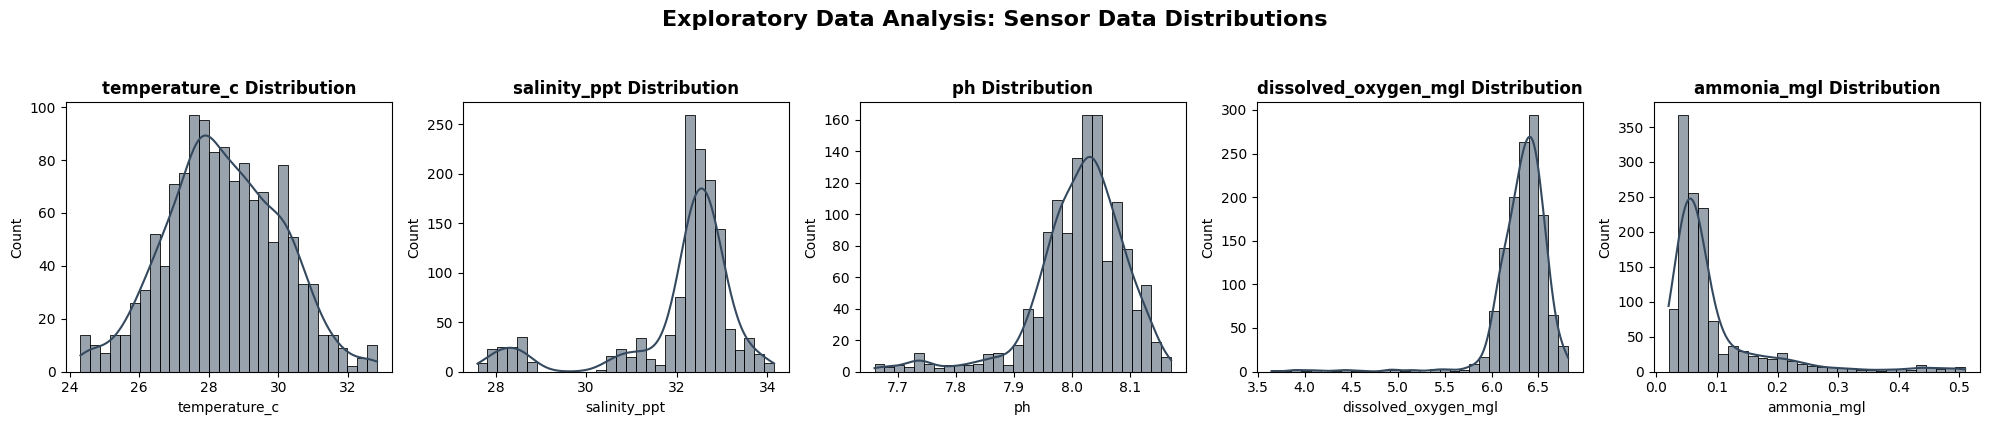

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import numpy as np
import warnings
warnings.filterwarnings("ignore")

# ---------------------------------------------------------
# 1. EXTRACT NUMERICAL FORECAST METRICS (1-HOUR AHEAD)
# ---------------------------------------------------------
# Load the JSON results generated by the pipeline
with open('../../Claude/results_ts_placeholder.json', 'r') as f:
    res = json.load(f)

# Get 1-Hour Horizon MAE for the 'Selected on validation' (Winning Models)
maes_1h = [m for m in res['test_MAE'] if m['horizon_h'] == 1]
print("--- Numerical Forecast Accuracy (1-Hour Ahead) ---")
for m in maes_1h:
    print(f"Sensor: {m['variable']}, Winning Model MAE: {m['Selected on validation']}")

# ---------------------------------------------------------
# 2. EXPLORATORY DATA ANALYSIS (EDA) PLOTS
# ---------------------------------------------------------
# Load the data
df = pd.read_csv('../../Claude/train_placeholder.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
sensors = ["temperature_c", "salinity_ppt", "ph", "dissolved_oxygen_mgl", "ammonia_mgl"]

# EDA Plot 1: Boxplots showing how each sensor behaves in Safe vs Critical states
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
palette = {'Optimal': '#2ecc71', 'Warning': '#f39c12', 'Critical': '#e74c3c'}

for i, s in enumerate(sensors):
    sns.boxplot(data=df, x='fuzzy_status', y=s, ax=axes[i], 
                order=['Optimal', 'Warning', 'Critical'], palette=palette)
    axes[i].set_title(f'{s} by AI Status', fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle("Exploratory Data Analysis: Sensor Value Ranges per Health Status", y=1.05, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# EDA Plot 2: Data Distributions (Histograms)
fig2, axes2 = plt.subplots(1, 5, figsize=(20, 4))

for i, s in enumerate(sensors):
    # Plot histogram with a KDE (Kernel Density Estimate) curve
    sns.histplot(df[s], kde=True, ax=axes2[i], color='#34495e', bins=30)
    axes2[i].set_title(f'{s} Distribution', fontweight='bold')

plt.suptitle("Exploratory Data Analysis: Sensor Data Distributions", y=1.05, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()